# 07 · Final pipeline: inference strategy + ensemble of detector families

No training here. The notebook takes the models already trained in notebooks 02, 03, 05 and 06 and asks three separate questions:

1. **Model effect:** how much changes when only the weights change, at the default inference of each model?
2. **Inference effect:** how much changes when the weights stay fixed and only the inference changes
   (larger test resolution, horizontal-flip TTA, tiled inference)?
3. **Ensemble effect:** how much is gained by fusing the boxes of different families with Weighted Boxes Fusion (WBF)?

All numbers use the same protocol as before: the 7 organiser val clips, original frames, `vd.coco_eval` (COCO mAP, 500 detections per image).

**Run:** Kaggle, GPU T4, Internet ON. Inputs: competition data + the outputs of notebook 02 (the version with the trained
`runs/yolo11s_1280` weights), 03 (`frcnn/`), 05 (`yolo_runs/`), 06 and 09 (`detr_runs/`) and 08 (`yolo_runs/`, YOLO11m). A model whose weights are not attached is skipped.
Predictions are cached in `preds07/`; attach this notebook's own output to a re-run and nothing is predicted twice.

In [1]:
# environment: Kaggle (data attached as inputs) or Google Colab (data downloaded with the Kaggle API)
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
COMP = "multiple-object-video-detection-hw-2-ucu-ai-2026"
if IN_COLAB:
    # needs the Colab secret KAGGLE_API_TOKEN (Kaggle → Settings → API → Generate New Token)
    from google.colab import userdata, drive
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    drive.mount("/content/drive")                                   # outputs go to Google Drive, so they survive a disconnect
    INPUT, WORK = Path("/content/input"), Path("/content/drive/MyDrive/visdrone_hw2")
    subprocess.run("pip install -q -U kaggle pycocotools", shell=True, check=True)
    if not (INPUT / "comp" / "test_images.csv").exists():
        (INPUT / "comp").mkdir(parents=True, exist_ok=True)
        subprocess.run(f"kaggle competitions download -c {COMP} -p {INPUT / 'comp'} && cd {INPUT / 'comp'} "
                       "&& unzip -q -o '*.zip' && rm -f *.zip", shell=True, check=True)
else:
    INPUT, WORK = Path("/kaggle/input"), Path("/kaggle/working")
    subprocess.run("pip install -q pycocotools", shell=True)
WORK.mkdir(parents=True, exist_ok=True); os.chdir(WORK)
print("Colab" if IN_COLAB else "Kaggle", "| outputs ->", WORK)

Kaggle | outputs -> /kaggle/working


In [2]:
%%writefile vd_utils.py
"""Shared helpers for the VisDrone-VID homework: data loading, COCO evaluation, submission writing."""
import json
from pathlib import Path

import numpy as np
import pandas as pd

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]


def find_data_root(start="/kaggle/input"):
    """Folder that contains train/, val/ and test/ (found by its train/annotations_coco.json)."""
    hits = sorted(Path(start).glob("**/train/annotations_coco.json"))
    if not hits:
        raise FileNotFoundError(f"train/annotations_coco.json not found under {start}: attach the competition data")
    return hits[0].parent.parent


def load_split(root, split):
    """COCO json of one split -> (images, annotations) DataFrames with 0-based `cls` and pixel boxes."""
    root = Path(root)
    coco = json.loads((root / split / "annotations_coco.json").read_text())
    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    if "video" in imgs:
        imgs["clip"] = imgs["video"].astype(str)
    else:
        imgs["clip"] = imgs["file_name"].map(lambda f: Path(f).parent.name)
    imgs["path"] = [_image_path(root, split, f) for f in imgs["file_name"]]

    anns = pd.DataFrame(coco["annotations"])
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns["iscrowd"] = anns.get("iscrowd", 0)
    anns["cls"] = anns["category_id"] - 1
    anns = anns.merge(imgs[["image_id", "clip", "width", "height"]], on="image_id")
    return imgs, anns


def _image_path(root, split, file_name):
    for p in (root / split / file_name, root / split / "images" / file_name, root / file_name):
        if p.exists():
            return str(p)
    raise FileNotFoundError(f"image {file_name} not found in {root / split}")


def coco_eval(gt_json, dets, img_ids=None, cat_ids=None, verbose=False):
    """COCO mAP with ignored regions (iscrowd=1) skipped and up to 500 detections per image.

    dets: list of dicts {image_id, category_id (1-based), bbox [x, y, w, h], score}.
    """
    import contextlib, io
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    quiet = contextlib.redirect_stdout(io.StringIO()) if not verbose else contextlib.nullcontext()
    with quiet:
        gt = COCO(str(gt_json))
        if not dets:
            return {k: 0.0 for k in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]}
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox")
        E.params.maxDets = [1, 100, 500]
        if img_ids is not None:
            E.params.imgIds = list(img_ids)
        if cat_ids is not None:
            E.params.catIds = list(cat_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    out = {k: float(v) for k, v in zip(["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"], s[:6])}
    # per-class AP[.5:.95] from the same evaluation: precision has shape [IoU, recall, class, area, maxDets]
    prec = E.eval["precision"][:, :, :, 0, -1]
    for k, cat in enumerate(E.params.catIds):
        p = prec[:, :, k]
        out[f"AP_{CLASSES[cat - 1]}"] = float(p[p > -1].mean()) if (p > -1).any() else float("nan")
    return out


def write_submission(dets, test_csv, out_path, max_dets=500):
    """dets: dict image_id (str, e.g. clip_001_0000001) -> array N x 6 [cls, score, x, y, w, h] in pixels."""
    test = pd.read_csv(test_csv)
    rows = []
    for image_id in test["image_id"]:
        d = np.asarray(dets.get(image_id, np.zeros((0, 6))), dtype=float).reshape(-1, 6)
        d = d[np.isfinite(d).all(1) & (d[:, 4] > 0) & (d[:, 5] > 0)]           # NaN / empty boxes make the file invalid
        d = d[(d[:, 0] >= 0) & (d[:, 0] < len(CLASSES))]          # e.g. RetinaNet's sigmoid head can output the unused label 0
        d = d[np.argsort(-d[:, 1])][:max_dets]
        rows.append(" ".join(f"{int(c)} {s:.4f} {x:.1f} {y:.1f} {w:.1f} {h:.1f}" for c, s, x, y, w, h in d))
    sub = pd.DataFrame({"image_id": test["image_id"], "PredictionString": rows})
    sub.to_csv(out_path, index=False)
    return sub


def build_yolo(root, out, step=4):
    """Same conversion as notebook 01: every `step`-th train frame, all val frames, ignored regions painted grey (114),
    boxes whose centre lies in an ignored region dropped. Used when notebook 01's output is not available (e.g. Colab)."""
    import shutil
    from PIL import Image
    out = Path(out)
    for split, st in [("train", step), ("val", 1)]:
        imgs, anns = load_split(root, split)
        (out / "images" / split).mkdir(parents=True, exist_ok=True); (out / "labels" / split).mkdir(parents=True, exist_ok=True)
        im = imgs.sort_values(["clip", "frame_id"]); im = im[im.groupby("clip").cumcount() % st == 0]
        by_img = dict(tuple(anns.groupby("image_id")))
        for r in im.itertuples():
            a = by_img.get(r.image_id, anns.iloc[:0])
            ig = a.loc[a.iscrowd == 1, ["x", "y", "w", "h"]].values; ob = a[a.iscrowd == 0]
            name = f"{r.clip}_{Path(r.file_name).stem}"; dst = out / "images" / split / f"{name}.jpg"
            if len(ig):
                px = np.array(Image.open(r.path).convert("RGB"))
                for x, y, w, h in ig.round().astype(int):
                    px[max(y, 0):y + h, max(x, 0):x + w] = 114
                Image.fromarray(px).save(dst, quality=95)
                cx, cy = (ob.x + ob.w / 2).values, (ob.y + ob.h / 2).values
                inside = ((cx[:, None] >= ig[:, 0]) & (cx[:, None] <= ig[:, 0] + ig[:, 2]) &
                          (cy[:, None] >= ig[:, 1]) & (cy[:, None] <= ig[:, 1] + ig[:, 3])).any(1)
                ob = ob[~inside]
            else:
                shutil.copy(r.path, dst)
            lines = [f"{c} {(x + w / 2) / r.width:.6f} {(y + h / 2) / r.height:.6f} {w / r.width:.6f} {h / r.height:.6f}"
                     for c, x, y, w, h in zip(ob.cls, ob.x, ob.y, ob.w, ob.h)]
            (out / "labels" / split / f"{name}.txt").write_text("\n".join(lines))
    (out / "data.yaml").write_text(f"path: {out}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(CLASSES))}\n")
    return out

Writing vd_utils.py


In [3]:
subprocess.run("pip install -q ultralytics", shell=True, check=True)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import gc, pickle, time
import cv2, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import torchvision.transforms.functional as TF
from torchvision.ops import batched_nms, box_iou
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from ultralytics import YOLO, RTDETR
import vd_utils as vd

ROOT = vd.find_data_root(INPUT)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
VAL_STEP = 1                                     # 2 = every 2nd val frame (halves the time; consecutive frames are near-duplicates)
val_imgs, _ = vd.load_split(ROOT, "val")
val_imgs = val_imgs.sort_values("image_id").iloc[::VAL_STEP]
VAL_GT = ROOT / "val" / "annotations_coco.json"
test = pd.read_csv(ROOT / "test_images.csv"); test["path"] = [str(ROOT / f) for f in test["file_name"]]
SPLITS = {"val": dict(zip(val_imgs["image_id"], val_imgs["path"])), "test": dict(zip(test["image_id"], test["path"]))}
CACHE = WORK / "preds07"; CACHE.mkdir(exist_ok=True)

def find_file(rel):
    hits = sorted(WORK.glob(rel)) + sorted(INPUT.glob(f"**/{rel}"))
    return hits[0] if hits else None
print("val frames:", len(val_imgs), "| test frames:", len(test), "| device:", DEVICE)

val frames: 2846 | test frames: 3811 | device: cuda


## 1. Trained models
| name | family | from | trained at |
|---|---|---|---|
| `yolo11s_e12_1280` | one-stage anchor-free | nb02 baseline, 12 epochs | 1280 |
| `yolo11s_e6_1536` | one-stage anchor-free | nb05, best YOLO on val | 1536 |
| `yolo11s_p2_e6_1280` | one-stage anchor-free, extra stride-4 head | nb05, best AP_small | 1280 |
| `yolo11m_e6_1536` | one-stage anchor-free, medium model | nb08 (same protocol as `yolo11s_e6_1536`) | 1536 |
| `frcnn_base` | two-stage anchor-based | nb03, best on val | 720 / 1280 |
| `rtdetr_q300`, `rtdetr_q500` | query-based transformer | nb06 | 1280 |
| `rtdetr_q300_5h` | query-based transformer, 5 h of training instead of 1 h | nb09 | 1280 |

RetinaNet (nb04) is left out: it was the weakest family (public LB 0.172) and its weights stayed on Google Drive.

In [4]:
MODELS = {   # name: (family, weight file written by an earlier notebook, default inference size)
    "yolo11s_e12_1280": ("YOLO", "runs/yolo11s_1280/weights/best.pt", 1280),
    "yolo11s_e6_1536": ("YOLO", "yolo_runs/yolo_s1536_e6/weights/best.pt", 1536),
    "yolo11s_p2_e6_1280": ("YOLO", "yolo_runs/yolo_p2_1280_e6/weights/best.pt", 1280),
    "yolo11m_e6_1536": ("YOLO", "yolo_runs/yolo_m1536_e6/weights/best.pt", 1536),
    "frcnn_base": ("FRCNN", "frcnn/frcnn_base.pt", 720),
    "rtdetr_q300": ("RTDETR", "detr_runs/rtdetr_q300/weights/best.pt", 1280),
    "rtdetr_q500": ("RTDETR", "detr_runs/rtdetr_q500/weights/best.pt", 1280),
    "rtdetr_q300_5h": ("RTDETR", "detr_runs/rtdetr_q300_5h/weights/best.pt", 1280),
}
WEIGHT = {m: find_file(rel) for m, (_, rel, _) in MODELS.items()}
for m, w in WEIGHT.items(): print(f"{m:20s}", w if w else "-- not attached, skipped")
MODELS = {m: v for m, v in MODELS.items() if WEIGHT[m]}

yolo11s_e12_1280     /kaggle/input/notebooks/yarema1234/notebooka290378ae2/runs/yolo11s_1280/weights/best.pt
yolo11s_e6_1536      -- not attached, skipped
yolo11s_p2_e6_1280   -- not attached, skipped
yolo11m_e6_1536      /kaggle/input/notebooks/yarema1234/08-yolo-m/yolo_runs/yolo_m1536_e6/weights/best.pt
frcnn_base           /kaggle/input/notebooks/yarema1234/03-faster-rcnn/frcnn/frcnn_base.pt
rtdetr_q300          /kaggle/input/notebooks/yarema1234/rt-detr-06/detr_runs/rtdetr_q300/weights/best.pt
rtdetr_q500          /kaggle/input/notebooks/yarema1234/rt-detr-06/detr_runs/rtdetr_q500/weights/best.pt
rtdetr_q300_5h       -- not attached, skipped


## 2. Inference functions
Every function returns `{image_id: array N × 6 [cls, score, x, y, w, h]}` in original pixels.

* **size:** the input resolution at test time. Objects are 10–30 px, so a larger input gives the network more pixels per object,
  at the cost of a scale shift from training.
* **flip:** the image is mirrored, predicted, and the boxes are mirrored back. Fused with the normal pass (below), it averages out
  part of the localisation noise and rescues objects found in only one of the two views.
* **tiles (SAHI-style):** the frame is cut into 2 × 2 tiles with 20 % overlap and every tile is predicted at 1280 px, so the frame is
  effectively seen at ~2× resolution. Boxes touching an inner tile border are dropped (the object is cut; the overlap guarantees that a
  small object is whole in a neighbouring tile), and the tiles are fused with a normal full-frame pass, which covers large objects.

In [5]:
def load_model(name):
    fam, _, _ = MODELS[name]
    if fam == "FRCNN":   # same architecture as notebook 03; the trained weights replace everything
        m = fasterrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, box_detections_per_img=500, box_score_thresh=0.001)
        m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, len(vd.CLASSES) + 1)
        m.load_state_dict(torch.load(WEIGHT[name], map_location=DEVICE))
        return m.to(DEVICE).eval()
    return (RTDETR if fam == "RTDETR" else YOLO)(WEIGHT[name])

def read_bgr(p, flip):
    im = cv2.imread(p)
    return np.ascontiguousarray(im[:, ::-1]) if flip else im

def unflip(d, W):
    d = d.copy(); d[:, 2] = W - d[:, 2] - d[:, 4]; return d

def ultra_predict(model, ims, size):
    # Ultralytics accepts a list of BGR arrays; small explicit chunks avoid GPU OOM
    out = []
    for k in range(0, len(ims), 4):
        for r in model.predict(ims[k:k + 4], imgsz=size, conf=0.001, iou=0.6, max_det=500, verbose=False):
            b = r.boxes; xyxy = b.xyxy.cpu().numpy()
            out.append(np.c_[b.cls.cpu().numpy(), b.conf.cpu().numpy(), xyxy[:, :2], xyxy[:, 2:] - xyxy[:, :2]])
    return out

@torch.no_grad()
def frcnn_predict(model, ims, size):
    model.transform.min_size, model.transform.max_size = (size,), int(round(size * 16 / 9))
    out = []
    for k in range(0, len(ims), 4):
        x = [TF.to_tensor(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)).to(DEVICE) for im in ims[k:k + 4]]
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            res = model(x)
        for r in res:
            b = r["boxes"].float().cpu().numpy()
            out.append(np.c_[r["labels"].cpu().numpy() - 1, r["scores"].float().cpu().numpy(), b[:, :2], b[:, 2:] - b[:, :2]])
    return out

def tiles_of(W, H, grid=2, overlap=0.2):
    tw, th = int(np.ceil(W / (grid - (grid - 1) * overlap))), int(np.ceil(H / (grid - (grid - 1) * overlap)))
    xs = np.linspace(0, W - tw, grid).astype(int); ys = np.linspace(0, H - th, grid).astype(int)
    return [(x, y, tw, th) for y in ys for x in xs]

def drop_cut(d, x0, y0, tw, th, W, H, m=2):
    # remove boxes touching a tile border that lies inside the image (the object continues outside the tile)
    x1, y1, x2, y2 = d[:, 2], d[:, 3], d[:, 2] + d[:, 4], d[:, 3] + d[:, 5]
    bad = ((x0 > 0) & (x1 < x0 + m)) | ((x0 + tw < W) & (x2 > x0 + tw - m)) | ((y0 > 0) & (y1 < y0 + m)) | ((y0 + th < H) & (y2 > y0 + th - m))
    return d[~bad]

def run_pass(model, fam, paths, size, flip=False, tiles=False, chunk=16):
    # one raw prediction pass over a list of images
    pred_fn = frcnn_predict if fam == "FRCNN" else ultra_predict
    out = []
    for k in range(0, len(paths), chunk):
        ims = [read_bgr(p, flip) for p in paths[k:k + chunk]]
        if not tiles:
            res = pred_fn(model, ims, size)
            out += [unflip(d, im.shape[1]) if flip else d for d, im in zip(res, ims)]
            continue
        for im in ims:                                  # 4 tiles of one frame form one batch
            H, W = im.shape[:2]; boxes = tiles_of(W, H)
            res = pred_fn(model, [im[y:y + th, x:x + tw] for x, y, tw, th in boxes], size)
            parts = []
            for (x, y, tw, th), d in zip(boxes, res):
                d = d.copy(); d[:, 2] += x; d[:, 3] += y
                parts.append(drop_cut(d, x, y, tw, th, W, H))
            out.append(np.concatenate(parts))
    return out

## 3. Box fusion (WBF) and a cache of raw passes
**Weighted Boxes Fusion** (Solovyev et al., 2019): boxes of the same class from all views are clustered (greedy, by IoU with the
highest-scored box of the cluster). Unlike NMS, which keeps only the best box of each cluster, WBF **averages the coordinates**
weighted by score, and the fused score is the mean over views, so a box confirmed by several models/views ranks higher than
a box found by one. Here the clustering reuses `batched_nms` (cluster heads = boxes NMS keeps), each view contributes at most its best
box per cluster, and the whole step is vectorised per image.

In [6]:
def fuse(views, weights=None, iou_thr=0.6, method="wbf", max_det=500):
    """views: list of N_i x 6 arrays [cls, score, x, y, w, h] for ONE image (one per model or TTA view)."""
    M = len(views); w_view = np.ones(M) if weights is None else np.asarray(weights, float)
    parts = [np.c_[v, np.full(len(v), i)] for i, v in enumerate(views) if len(v)]
    if not parts: return np.zeros((0, 6))
    D = np.concatenate(parts)
    xyxy = np.c_[D[:, 2:4], D[:, 2:4] + D[:, 4:6]]
    b, s, c = torch.from_numpy(xyxy).float(), torch.from_numpy(D[:, 1]).float(), torch.from_numpy(D[:, 0]).long()
    heads = batched_nms(b, s, c, iou_thr).numpy()                       # one head per cluster, best score first
    if method == "nms": return D[heads[:max_det], :6]
    iou = box_iou(b, b[heads]).numpy()
    iou[D[:, 0][:, None] != D[heads, 0][None, :]] = -1                   # clusters never mix classes
    cl = iou.argmax(1)                                                   # every box joins the head it overlaps most
    order = np.argsort(-D[:, 1], kind="stable")
    _, first = np.unique(cl[order] * M + D[order, 6].astype(int), return_index=True)
    sel = order[first]                                                   # the best box of each view inside each cluster
    k, ws = cl[sel], w_view[D[sel, 6].astype(int)] * D[sel, 1]
    n = len(heads); wsum = np.maximum(np.bincount(k, ws, n), 1e-12)
    box = np.stack([np.bincount(k, ws * xyxy[sel, j], n) for j in range(4)], 1) / wsum[:, None]
    score = wsum / w_view.sum()
    out = np.c_[D[heads, 0], score, box[:, :2], box[:, 2:] - box[:, :2]]
    return out[np.argsort(-score)[:max_det]]

def fuse_preds(pred_list, weights=None, iou_thr=0.6, method="wbf"):
    return {i: fuse([p[i] for p in pred_list], weights, iou_thr, method) for i in pred_list[0]}

_LOADED, TIMES = [None, None], {}
def raw(name, size, flip=False, tiles=False, split="val"):
    # cached raw pass: preds07/<split>_<name>@<size>[_flip][_tiles].pkl, also looked up in attached inputs
    key = f"{name}@{size}" + ("_flip" if flip else "") + ("_tiles" if tiles else "")
    f = find_file(f"preds07/{split}_{key}.pkl")
    if f is not None:
        P = pickle.load(open(f, "rb"))
        if set(SPLITS[split]) <= set(P): return {i: P[i] for i in SPLITS[split]}
    if _LOADED[0] != name:
        _LOADED[1] = None; gc.collect(); torch.cuda.empty_cache()
        _LOADED[:] = [name, load_model(name)]
    ids, paths = list(SPLITS[split]), list(SPLITS[split].values())
    t0 = time.time()
    P = dict(zip(ids, run_pass(_LOADED[1], MODELS[name][0], paths, size, flip, tiles)))
    TIMES[f"{split}_{key}"] = (time.time() - t0) / len(ids) * 1000
    pickle.dump(P, open(CACHE / f"{split}_{key}.pkl", "wb"))
    return P

def setting(name, size=None, flip=False, tiles=False, split="val"):
    # an inference setting = one or more raw passes of the same weights, fused with WBF
    size = size or MODELS[name][2]
    views = [raw(name, size, split=split)]
    if flip: views.append(raw(name, size, flip=True, split=split))
    if tiles: views.append(raw(name, 1280, tiles=True, split=split))
    return views[0] if len(views) == 1 else fuse_preds(views)

def to_coco(P):
    return [{"image_id": int(i), "category_id": int(c) + 1, "bbox": [float(x), float(y), float(w), float(h)], "score": float(s)}
            for i, d in P.items() for c, s, x, y, w, h in d]

ROWS = {}
def evaluate(label, P, **info):
    ROWS[label] = {**info, **vd.coco_eval(VAL_GT, to_coco(P), img_ids=[int(i) for i in SPLITS["val"]])}
    pd.DataFrame(ROWS).T.to_csv(WORK / "results_07.csv")
    r = ROWS[label]; print(f"{label:45s} mAP {r['mAP']:.4f} | AP50 {r['AP50']:.4f} | AP_small {r['AP_small']:.4f}")
    return r["mAP"]

## 4. Model effect: every model at its default inference
Same images, same evaluation, default test size of each model, no TTA. Only the weights differ.

In [7]:
SPEC, BEST_SPEC = {}, {}                                  # label -> (model, size, flip, tiles); best setting per model
for m, (fam, _, size) in MODELS.items():
    lab = f"{m} | default"
    SPEC[lab] = (m, size, False, False)
    BEST_SPEC[m] = (evaluate(lab, setting(m), group="model", family=fam), lab)
MAIN = ["group", "mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]
display(pd.DataFrame(ROWS).T[MAIN].round(4))

yolo11s_e12_1280 | default                    mAP 0.1984 | AP50 0.3949 | AP_small 0.1077
yolo11m_e6_1536 | default                     mAP 0.2254 | AP50 0.4484 | AP_small 0.1244
frcnn_base | default                          mAP 0.2245 | AP50 0.4584 | AP_small 0.1046
rtdetr_q300 | default                         mAP 0.2904 | AP50 0.5540 | AP_small 0.1584
rtdetr_q500 | default                         mAP 0.2746 | AP50 0.5269 | AP_small 0.1361


,group,mAP,AP50,AP75,AP_small,AP_medium,AP_large
yolo11s_e12_1280 | default,model,0.198408,0.394923,0.17391,0.107743,0.184173,0.361922
yolo11m_e6_1536 | default,model,0.225354,0.448449,0.200342,0.124368,0.233089,0.323387
frcnn_base | default,model,0.224458,0.458436,0.194414,0.104561,0.205667,0.416628
rtdetr_q300 | default,model,0.290379,0.553957,0.264668,0.158405,0.251707,0.458388
rtdetr_q500 | default,model,0.274638,0.526877,0.24931,0.136068,0.244805,0.456653


## 5. Inference effect: same weights, different inference
Applied to the best model of each family. RT-DETR accepts other input sizes too: Ultralytics recomputes its sine position
embeddings for the actual feature-map size, so a larger test size and tiles are possible without retraining.

| setting | YOLO | RT-DETR | Faster R-CNN |
|---|---|---|---|
| larger test size | 1536 → 1920 | 1280 → 1536 | shorter side 720 → 900 |
| flip TTA | normal + mirrored pass, WBF | same | same |
| tiles | full frame + 2 × 2 tiles at 1280, WBF | same | – (the RoI head already samples 7 × 7 features per proposal; tiles at 2 s per frame are not affordable) |
| combined | best size + every option that helped alone | same | same |

In [8]:
yolos = [m for m in MODELS if MODELS[m][0] == "YOLO"]
STRAT = {}
if yolos:
    y = max(yolos, key=lambda m: BEST_SPEC[m][0])
    STRAT[y] = dict(size=[1920 if MODELS[y][2] >= 1536 else 1536], flip=True, tiles=True)
detrs = [m for m in MODELS if MODELS[m][0] == "RTDETR"]
if detrs:
    d = max(detrs, key=lambda m: BEST_SPEC[m][0])
    STRAT[d] = dict(size=[1536], flip=True, tiles=True)
if "frcnn_base" in MODELS:
    STRAT["frcnn_base"] = dict(size=[900], flip=True, tiles=False)

for m, opt in STRAT.items():
    base_size, base_map = MODELS[m][2], BEST_SPEC[m][0]
    gains = {}
    for s in opt["size"]:
        lab = f"{m} | size {s}"; SPEC[lab] = (m, s, False, False)
        gains[("size", s)] = evaluate(lab, setting(m, size=s), group="inference", family=MODELS[m][0]) - base_map
    for o in ["flip", "tiles"]:
        if opt[o]:
            lab = f"{m} | {o}"; SPEC[lab] = (m, base_size, o == "flip", o == "tiles")
            gains[o] = evaluate(lab, setting(m, **{o: True}), group="inference", family=MODELS[m][0]) - base_map
    # combination: the better size + every option that improved mAP on its own
    best_size = max([base_size] + opt["size"], key=lambda s: gains.get(("size", s), 0))
    flip, tiles = gains.get("flip", 0) > 0, gains.get("tiles", 0) > 0
    if (best_size != base_size) + flip + tiles >= 2:
        lab = f"{m} | size {best_size}" + (" + flip" if flip else "") + (" + tiles" if tiles else "")
        SPEC[lab] = (m, best_size, flip, tiles)
        evaluate(lab, setting(m, best_size, flip, tiles), group="inference", family=MODELS[m][0])
    for lab, r in ROWS.items():                                    # remember the best setting of this model
        if lab.startswith(m + " |") and r["mAP"] > BEST_SPEC[m][0]: BEST_SPEC[m] = (r["mAP"], lab)

R = pd.DataFrame(ROWS).T
display(R[MAIN].round(4))
print("best setting per model:"); [print(f"  {v[1]:45s} {v[0]:.4f}") for v in BEST_SPEC.values()]
print("ms / image of each raw pass (incl. disk):", {k: round(v) for k, v in TIMES.items()})

yolo11m_e6_1536 | size 1920                   mAP 0.2258 | AP50 0.4504 | AP_small 0.1399
yolo11m_e6_1536 | flip                        mAP 0.2402 | AP50 0.4755 | AP_small 0.1292
yolo11m_e6_1536 | tiles                       mAP 0.2416 | AP50 0.4763 | AP_small 0.1481
yolo11m_e6_1536 | size 1920 + flip + tiles    mAP 0.2457 | AP50 0.4839 | AP_small 0.1538
rtdetr_q300 | size 1536                       mAP 0.2940 | AP50 0.5566 | AP_small 0.1708
rtdetr_q300 | flip                            mAP 0.2980 | AP50 0.5673 | AP_small 0.1637
rtdetr_q300 | tiles                           mAP 0.3081 | AP50 0.5820 | AP_small 0.1984
rtdetr_q300 | size 1536 + flip + tiles        mAP 0.3095 | AP50 0.5834 | AP_small 0.1953
frcnn_base | size 900                         mAP 0.2290 | AP50 0.4678 | AP_small 0.1090
frcnn_base | flip                             mAP 0.2365 | AP50 0.4786 | AP_small 0.1131
frcnn_base | size 900 + flip                  mAP 0.2400 | AP50 0.4877 | AP_small 0.1140
best setting per mode

,group,mAP,AP50,AP75,AP_small,AP_medium,AP_large
yolo11s_e12_1280 | default,model,0.198408,0.394923,0.17391,0.107743,0.184173,0.361922
yolo11m_e6_1536 | default,model,0.225354,0.448449,0.200342,0.124368,0.233089,0.323387
frcnn_base | default,model,0.224458,0.458436,0.194414,0.104561,0.205667,0.416628
rtdetr_q300 | default,model,0.290379,0.553957,0.264668,0.158405,0.251707,0.458388
rtdetr_q500 | default,model,0.274638,0.526877,0.24931,0.136068,0.244805,0.456653
yolo11m_e6_1536 | size 1920,inference,0.225836,0.450384,0.19857,0.139874,0.244725,0.311068
yolo11m_e6_1536 | flip,inference,0.240176,0.475468,0.214733,0.12918,0.245538,0.343979
yolo11m_e6_1536 | tiles,inference,0.241637,0.476315,0.216527,0.148111,0.254321,0.33775
yolo11m_e6_1536 | size 1920 + flip + tiles,inference,0.245719,0.483913,0.220258,0.153763,0.259039,0.339536
rtdetr_q300 | size 1536,inference,0.294011,0.556614,0.274702,0.170786,0.261084,0.460607


## 6. Ensemble effect: WBF across models
Candidates: every model with its best inference setting from sections 4–5. **Greedy forward selection:** start from the best single
setting, add the candidate that raises val mAP the most, stop when the gain is below 0.002. Weights are equal (one more
tuned parameter per model would mostly fit the 7 val clips). Then the fusion IoU threshold and WBF vs plain NMS are compared on the selected set.

In [9]:
CAND = {m: BEST_SPEC[m][1] for m in MODELS}
VAL_P = {m: setting(*SPEC[lab]) for m, lab in CAND.items()}
chosen = [max(CAND, key=lambda m: BEST_SPEC[m][0])]; cur = BEST_SPEC[chosen[0]][0]
print("start:", CAND[chosen[0]], round(cur, 4))
while len(chosen) < len(CAND):
    trial = {}
    for m in CAND:
        if m in chosen: continue
        P = fuse_preds([VAL_P[x] for x in chosen + [m]])
        trial[m] = evaluate("ens | " + " + ".join(chosen + [m]), P, group="ensemble", family="mixed")
    m, v = max(trial.items(), key=lambda t: t[1])
    if v - cur < 0.002: print("stop: best addition", m, f"{v - cur:+.4f}"); break
    chosen.append(m); cur = v; print("add", m, f"-> {v:.4f}")

FUSE_CFG = dict(iou_thr=0.6, method="wbf")
if len(chosen) > 1:
    for thr in [0.5, 0.7]:
        v = evaluate(f"ens | selected, WBF iou {thr}", fuse_preds([VAL_P[x] for x in chosen], iou_thr=thr), group="ensemble", family="mixed")
        if v > cur: cur, FUSE_CFG = v, dict(iou_thr=thr, method="wbf")
    v = evaluate("ens | selected, NMS iou 0.6", fuse_preds([VAL_P[x] for x in chosen], method="nms"), group="ensemble", family="mixed")
    if v > cur: cur, FUSE_CFG = v, dict(iou_thr=0.6, method="nms")
print("selected:", chosen, FUSE_CFG, f"val mAP {cur:.4f}")

# a second ensemble that is NOT selected on val: all models, default inference, WBF (hedge against overfitting the 7 val clips)
ALL_DEFAULT = [setting(m) for m in MODELS]
evaluate("ens | all models, default inference", fuse_preds(ALL_DEFAULT), group="ensemble", family="mixed")

start: rtdetr_q300 | size 1536 + flip + tiles 0.3095
ens | rtdetr_q300 + yolo11s_e12_1280          mAP 0.2980 | AP50 0.5686 | AP_small 0.1849
ens | rtdetr_q300 + yolo11m_e6_1536           mAP 0.3092 | AP50 0.5837 | AP_small 0.1888
ens | rtdetr_q300 + frcnn_base                mAP 0.3028 | AP50 0.5788 | AP_small 0.1556
ens | rtdetr_q300 + rtdetr_q500               mAP 0.3090 | AP50 0.5827 | AP_small 0.1854
stop: best addition yolo11m_e6_1536 -0.0003
selected: ['rtdetr_q300'] {'iou_thr': 0.6, 'method': 'wbf'} val mAP 0.3095
ens | all models, default inference           mAP 0.3028 | AP50 0.5743 | AP_small 0.1657


0.3028323415405157

## 7. Summary: what each step contributes

,step,setting,mAP,AP50,AP_small,AP_medium,AP_large,Δ mAP vs previous
0,baseline (nb02),yolo11s_e12_1280 | default,0.1984,0.3949,0.1077,0.1842,0.3619,NaN
1,model change,rtdetr_q300 | default,0.2904,0.5540,0.1584,0.2517,0.4584,0.0920
2,inference change,rtdetr_q300 | size 1536 + flip + tiles,0.3095,0.5834,0.1953,0.2770,0.4818,0.0191
3,ensemble,ens | rtdetr_q300 + yolo11m_e6_1536,0.3092,0.5837,0.1888,0.2903,0.4633,-0.0003


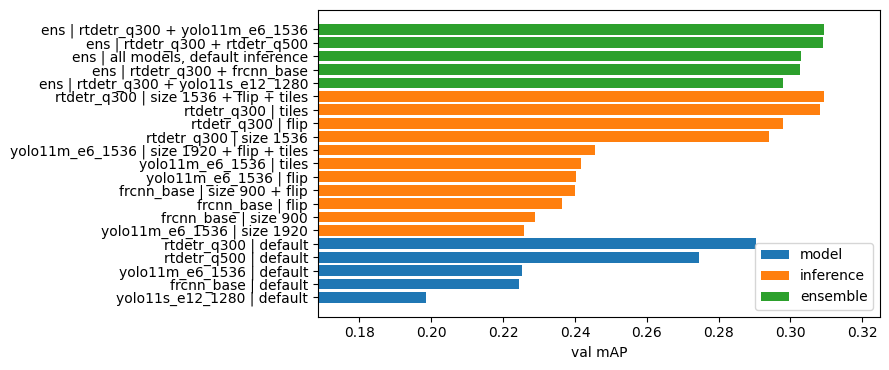

,rtdetr_q300 | default,rtdetr_q300 | size 1536 + flip + tiles,ens | rtdetr_q300 + yolo11m_e6_1536
AP_person,0.309,0.316,0.328
AP_bicycle,0.256,0.273,0.297
AP_car,0.457,0.477,0.479
AP_van,0.304,0.324,0.316
AP_truck,0.316,0.352,0.349
AP_tricycle,0.267,0.311,0.334
AP_bus,0.278,0.271,0.214
AP_motor,0.140,0.155,0.163


In [10]:
R = pd.DataFrame(ROWS).T
base_lab = "yolo11s_e12_1280 | default" if "yolo11s_e12_1280 | default" in R.index else R.index[0]
best_model_lab = R[R.group == "model"]["mAP"].astype(float).idxmax()
best_m = SPEC[best_model_lab][0]
best_inf_lab = BEST_SPEC[best_m][1]
ens_lab = R[R.group == "ensemble"]["mAP"].astype(float).idxmax()
steps = pd.DataFrame({
    "step": ["baseline (nb02)", "model change", "inference change", "ensemble"],
    "setting": [base_lab, best_model_lab, best_inf_lab, ens_lab]})
steps = steps.join(R.loc[steps.setting, ["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]].astype(float).reset_index(drop=True))
steps["Δ mAP vs previous"] = steps["mAP"].diff()
display(steps.round(4))

fig, ax = plt.subplots(figsize=(9, 3.8))
for g, col in [("model", "tab:blue"), ("inference", "tab:orange"), ("ensemble", "tab:green")]:
    s = R[R.group == g]["mAP"].astype(float).sort_values()
    ax.barh(s.index, s.values, color=col, label=g)
ax.set_xlabel("val mAP"); ax.legend(loc="lower right"); ax.set_xlim(left=max(0, R["mAP"].astype(float).min() - 0.03))
plt.tight_layout(); plt.savefig(WORK / "summary_07.png", dpi=120); plt.show()

# per-class AP: best single model (default inference) vs the selected ensemble
display(R.loc[[best_model_lab, best_inf_lab, ens_lab], [f"AP_{c}" for c in vd.CLASSES]].astype(float).T.round(3))

## 8. Test submissions
* `submission_A_ensemble.csv` — the ensemble selected on val (section 6)
* `submission_B_all_default.csv` — all models, default inference, WBF (not selected on val)
* `submission_C_single.csv` — the best single model with its best inference setting

The two final Kaggle submissions should be chosen by val mAP (table above) together with the public score, not by the public score alone:
the public part is ~30 % of the test clips.

In [11]:
def test_setting(lab):
    m, size, flip, tiles = SPEC[lab]
    return setting(m, size, flip, tiles, split="test")

def submit(P, name):
    vd.write_submission(P, ROOT / "test_images.csv", WORK / name); print("written", name)

submit(fuse_preds([test_setting(CAND[m]) for m in chosen], **FUSE_CFG) if len(chosen) > 1 else test_setting(CAND[chosen[0]]),
       "submission_A_ensemble.csv")
submit(fuse_preds([setting(m, split="test") for m in MODELS]), "submission_B_all_default.csv")
submit(test_setting(best_inf_lab), "submission_C_single.csv")

written submission_A_ensemble.csv
written submission_B_all_default.csv
written submission_C_single.csv
